In [26]:
# problem statement

# Bike rental companies need to manage bicycle availability
#  efficiently because demand varies with time, weather, and working days.
# This project predicts the "number of bikes rented per hour" using
#  historical rental data and relevant features.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# for linear trend forecasting

from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error



In [4]:
df=pd.read_csv("/content/day.csv")
df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,726,27-12-2019,1,1,12,0,4,1,2,10.420847,11.33210,65.2917,23.458911,247,1867,2114
726,727,28-12-2019,1,1,12,0,5,1,2,10.386653,12.75230,59.0000,10.416557,644,2451,3095
727,728,29-12-2019,1,1,12,0,6,0,2,10.386653,12.12000,75.2917,8.333661,159,1182,1341
728,729,30-12-2019,1,1,12,0,0,0,1,10.489153,11.58500,48.3333,23.500518,364,1432,1796


In [5]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [6]:
df.tail()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
725,726,27-12-2019,1,1,12,0,4,1,2,10.420847,11.33210,65.2917,23.458911,247,1867,2114
726,727,28-12-2019,1,1,12,0,5,1,2,10.386653,12.75230,59.0000,10.416557,644,2451,3095
727,728,29-12-2019,1,1,12,0,6,0,2,10.386653,12.12000,75.2917,8.333661,159,1182,1341
728,729,30-12-2019,1,1,12,0,0,0,1,10.489153,11.58500,48.3333,23.500518,364,1432,1796
729,730,31-12-2019,1,1,12,0,1,1,2,8.849153,11.17435,57.7500,10.374682,439,2290,2729


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


In [8]:
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [13]:
# features required for model inputs

# features = ["season", "yr", "mnth", "holiday","weekday", "workingday", "weathersit",
#             "temp", "atemp", "hum", "windspeed", "day"]

# Let's do Feature engineering

# convert date column into datetime format with dayfirst=True
df['dteday']=pd.to_datetime(df['dteday'], dayfirst=True)

#sort values chronologically past values first and new values last

df=df.sort_values("dteday").reset_index(drop=True)

df.shape

(730, 16)

In [14]:
# extract useful data  from date feature

df["day"]=df["dteday"].dt.day
df["month"]=df["dteday"].dt.month
df["year"]=df["dteday"].dt.year
df["dayofweek"]=df["dteday"].dt.dayofweek
df["dayofyear"]=df["dteday"].dt.dayofyear

# Weekend Indicator: Monday-0 and Saturday-6
df['is_weekend']=(df['weekday']>=5).astype(int)

print(df[['dteday','month','year','dayofyear','is_weekend']].head())

      dteday  month  year  dayofyear  is_weekend
0 2018-01-01      1  2018          1           1
1 2018-01-02      1  2018          2           0
2 2018-01-03      1  2018          3           0
3 2018-01-04      1  2018          4           0
4 2018-01-05      1  2018          5           0


In [20]:
# let select features and target(output)

features=[ 'is_weekend','dayofyear','year', 'month', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'hum', 'windspeed']


X=df[features]

y=df['cnt']

print(x.shape)
print(y.shape)


(730, 11)
(730,)


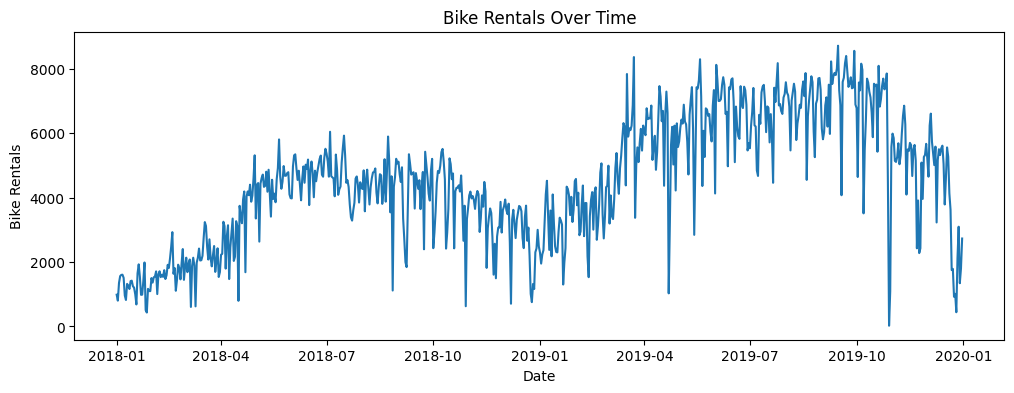

In [21]:
plt.figure(figsize=(12,4))

plt.plot(df['dteday'], df['cnt'])

plt.xlabel('Date')
plt.ylabel('Bike Rentals')
plt.title('Bike Rentals Over Time')
plt.show()


In [22]:
# Chronological split

# without splitting by random, split data based on older dates

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Last training date:",
      df["dteday"].iloc[split_index - 1])

print("First testing date:",
      df["dteday"].iloc[split_index])


Training records: 584
Testing records: 146
Last training date: 2019-08-07 00:00:00
First testing date: 2019-08-08 00:00:00


In [23]:
# Create the model
model = LinearRegression()

# Train using historical data
model.fit(X_train, y_train)

# Predict bike rentals for test dates
y_pred = model.predict(X_test)

print("Model training completed!")
print("First 10 predictions:")
print(y_pred[:10].round(0))

Model training completed!
First 10 predictions:
[6892. 7386. 6466. 6348. 7030. 7209. 7059. 7044. 7298. 7131.]


In [38]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse,2))
print("R2 Score:", round(r2))

MAE : 948.65
RMSE: 1283.39
R2 Score: 1


In [28]:
# MAE	Average prediction error in number of bikes
# RMSE	Gives larger errors more penalty
# R²	How well the model explains variation in rental demand

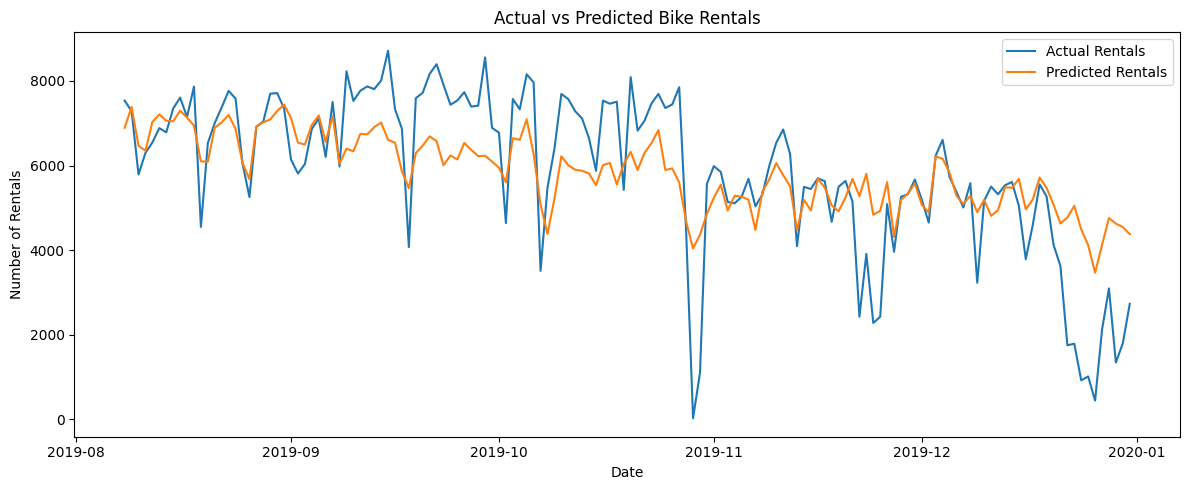

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df["dteday"].iloc[split_index:],
    y_test.values,
    label="Actual Rentals"
)

plt.plot(
    df["dteday"].iloc[split_index:],
    y_pred,
    label="Predicted Rentals"
)

plt.title("Actual vs Predicted Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Number of Rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Get date from user
date_input = input("Enter forecast date (YYYY-MM-DD): ")
forecast_date = pd.to_datetime(date_input)

# Automatically derive date features
is_weekend = int(forecast_date.weekday() >= 5)
dayofyear = forecast_date.dayofyear
year = forecast_date.year
month = forecast_date.month
weekday = forecast_date.weekday()

# Get remaining inputs from user
holiday = int(input("Is it a holiday? (1 = Yes, 0 = No): "))
workingday = int(input("Is it a working day? (1 = Yes, 0 = No): "))

weathersit = int(input(
    "Weather (1 = Clear, 2 = Mist/Cloudy, 3 = Light rain/snow, 4 = Heavy rain/snow): "
))

temp = float(input("Enter normalized temperature (0 to 1): "))
hum = float(input("Enter normalized humidity (0 to 1): "))
windspeed = float(input("Enter normalized windspeed (0 to 1): "))

# Arrange inputs in the exact training feature order
user_data = pd.DataFrame([{
    "is_weekend": is_weekend,
    "dayofyear": dayofyear,
    "year": year,
    "month": month,
    "holiday": holiday,
    "weekday": weekday,
    "workingday": workingday,
    "weathersit": weathersit,
    "temp": temp,
    "hum": hum,
    "windspeed": windspeed
}])

# Predict rental demand
prediction = model.predict(user_data)[0]

# Rental count cannot be negative
prediction = max(0, round(prediction))

print("\n----- BikeShare ForecastAI -----")
print("Forecast Date:", forecast_date.date())
print("Predicted Bike Rentals:", prediction)
print("--------------------------------")

Enter forecast date (YYYY-MM-DD): 12-04-2019
Is it a holiday? (1 = Yes, 0 = No): 1
Is it a working day? (1 = Yes, 0 = No): 0
Weather (1 = Clear, 2 = Mist/Cloudy, 3 = Light rain/snow, 4 = Heavy rain/snow): 1
Enter normalized temperature (0 to 1): 1
Enter normalized humidity (0 to 1): 0
Enter normalized windspeed (0 to 1): 1

----- BikeShare ForecastAI -----
Forecast Date: 2019-12-04
Predicted Bike Rentals: 4362
--------------------------------
